In [ ]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FILES = [
    "umkm_provinsi.csv",
    "internet.csv",
    "jumlah-merchant-qris-per-provinsi-_31-maret-2025_.csv",
    "ekonomi.csv",
]
for f in FILES:
    print(f"{f:60s} ada: {os.path.exists(f)}")


umkm_provinsi.csv                                            ada: True
internet.csv                                                 ada: True
jumlah-merchant-qris-per-provinsi-_31-maret-2025_.csv        ada: True
ekonomi.csv                                                  ada: True


In [ ]:
PROVINSI = [
 "ACEH","SUMATERA UTARA","SUMATERA BARAT","RIAU","JAMBI","SUMATERA SELATAN","BENGKULU","LAMPUNG",
 "KEPULAUAN BANGKA BELITUNG","KEPULAUAN RIAU","DKI JAKARTA","JAWA BARAT","JAWA TENGAH","DI YOGYAKARTA",
 "JAWA TIMUR","BANTEN","BALI","NUSA TENGGARA BARAT","NUSA TENGGARA TIMUR","KALIMANTAN BARAT",
 "KALIMANTAN TENGAH","KALIMANTAN SELATAN","KALIMANTAN TIMUR","KALIMANTAN UTARA","SULAWESI UTARA",
 "SULAWESI TENGAH","SULAWESI SELATAN","SULAWESI TENGGARA","GORONTALO","SULAWESI BARAT","MALUKU",
 "MALUKU UTARA","PAPUA BARAT","PAPUA BARAT DAYA","PAPUA","PAPUA SELATAN","PAPUA TENGAH","PAPUA PEGUNUNGAN",
]
ALIAS = {
 "DAERAH ISTIMEWA YOGYAKARTA":"DI YOGYAKARTA","D I YOGYAKARTA":"DI YOGYAKARTA","YOGYAKARTA":"DI YOGYAKARTA","DIY":"DI YOGYAKARTA",
 "KEP RIAU":"KEPULAUAN RIAU","KEP BANGKA BELITUNG":"KEPULAUAN BANGKA BELITUNG","BANGKA BELITUNG":"KEPULAUAN BANGKA BELITUNG",
 "JAKARTA":"DKI JAKARTA","DKI":"DKI JAKARTA","NTB":"NUSA TENGGARA BARAT","NTT":"NUSA TENGGARA TIMUR",
}
def bersihkan_nama(x):
    if pd.isna(x): return np.nan
    s = str(x).upper()
    s = re.sub(r"[^A-Z ]", " ", s)
    s = re.sub(r"\b(PROVINSI|PROV)\b", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return ALIAS.get(s, s)

umkm   = pd.read_csv("umkm_provinsi.csv")
internet = pd.read_csv("internet.csv")
qris   = pd.read_csv("jumlah-merchant-qris-per-provinsi-_31-maret-2025_.csv")
eko    = pd.read_csv("ekonomi.csv")

umkm["provinsi"]   = umkm["provinsi"].map(bersihkan_nama)
internet["provinsi"] = internet["provinsi"].map(bersihkan_nama)
qris["provinsi"]   = qris["provinsi"].map(bersihkan_nama)
eko["provinsi"]    = eko["provinsi"].map(bersihkan_nama)

internet = internet[internet["provinsi"] != "INDONESIA"]
eko = eko.dropna(how="all")

df = (pd.DataFrame({"provinsi": PROVINSI})
      .merge(umkm[["provinsi","mikro","kecil","menengah","umk","total_nib"]], on="provinsi", how="left")
      .merge(internet[["provinsi","pct_internet"]], on="provinsi", how="left")
      .merge(qris[["provinsi","merchant_qris"]], on="provinsi", how="left")
      .merge(eko[["provinsi","pdrb_per_kapita","penduduk"]], on="provinsi", how="left"))

df["total_usaha"]   = df["umk"]
df["densitas_usaha"] = df["total_usaha"] / df["penduduk"] * 1000
df["qris_per_1000"] = df["merchant_qris"] / df["penduduk"] * 1000

print("Total provinsi:", len(df))
print("\nData terisi per kolom:")
print(df.notna().sum())

Total provinsi: 38

Data terisi per kolom:
provinsi           38
mikro              38
kecil              38
menengah           38
umk                38
total_nib          38
pct_internet       38
merchant_qris      34
pdrb_per_kapita    38
penduduk           38
total_usaha        38
densitas_usaha     38
qris_per_1000      34
dtype: int64


In [ ]:
from sklearn.preprocessing import MinMaxScaler

AMBANG = 10_000
KEY = ["total_usaha","densitas_usaha","pct_internet","qris_per_1000","pdrb_per_kapita"]
kosong = df[KEY].isna()
gugur = kosong.any(axis=1) | (df["total_usaha"] < AMBANG)
df_layak = df[~gugur].reset_index(drop=True)

FITUR = {
    "ukuran_pasar": "total_usaha",
    "kepadatan_usaha": "densitas_usaha",
    "kesiapan_digital": "pct_internet",
    "adopsi_pembayaran_digital": "qris_per_1000",
    "aktivitas_ekonomi": "pdrb_per_kapita",
}
df_layak["ukuran_pasar_log"] = np.log1p(df_layak["total_usaha"])

scaler = MinMaxScaler()
norm = pd.DataFrame(
    scaler.fit_transform(df_layak[list(FITUR.values())]),
    columns=[f"{k}_norm" for k in FITUR],
    index=df_layak.index,
)
df_model = pd.concat([df_layak, norm], axis=1)
df_model.to_csv("data_siap_model.csv", index=False)

print("Layak diranking:", len(df_model))
print(df_model[[c for c in df_model.columns if c.endswith('_norm')]].describe().loc[["min","max"]])

Layak diranking: 31
     ukuran_pasar_norm  kepadatan_usaha_norm  kesiapan_digital_norm  \
min                0.0                   0.0                    0.0   
max                1.0                   1.0                    1.0   

     adopsi_pembayaran_digital_norm  aktivitas_ekonomi_norm  
min                             0.0                     0.0  
max                             1.0                     1.0  


,k,inertia,silhouette
0,2,4.420242,0.441526
1,3,3.083202,0.456720
2,4,2.020477,0.359325
3,5,1.483978,0.377937
4,6,1.129806,0.343911


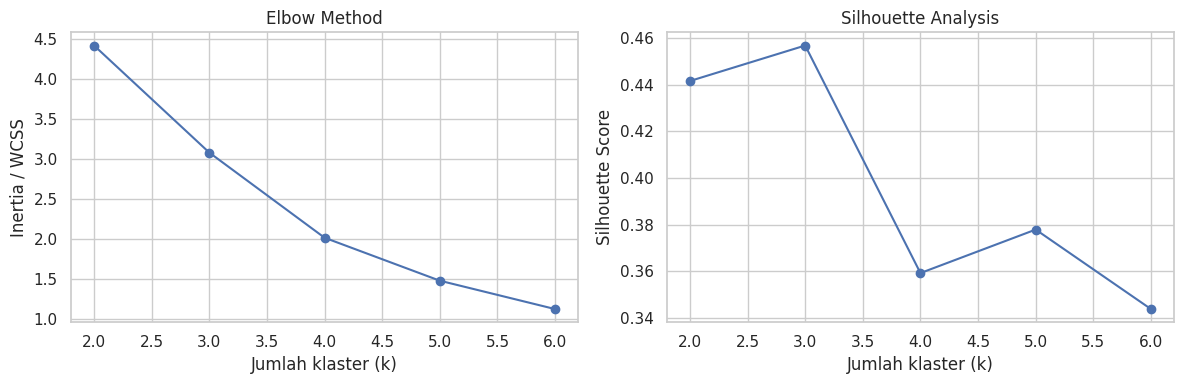

Profil rata-rata per klaster:


,ukuran_pasar_norm,kepadatan_usaha_norm,kesiapan_digital_norm,adopsi_pembayaran_digital_norm,aktivitas_ekonomi_norm,skor_icp
cluster,,,,,,
0,0.073,0.425,0.504,0.133,0.129,0.244
1,0.091,0.693,0.890,0.471,0.643,0.483
2,0.772,0.458,0.403,0.168,0.125,0.480



Anggota tiap klaster:
Klaster 0 (C - Wilayah Rintisan Digital): ACEH, SUMATERA UTARA, SUMATERA BARAT, RIAU, JAMBI, SUMATERA SELATAN, BENGKULU, LAMPUNG, KEPULAUAN BANGKA BELITUNG, DI YOGYAKARTA, BANTEN, BALI, NUSA TENGGARA BARAT, NUSA TENGGARA TIMUR, KALIMANTAN BARAT, KALIMANTAN TENGAH, KALIMANTAN SELATAN, SULAWESI UTARA, SULAWESI TENGAH, SULAWESI SELATAN, SULAWESI TENGGARA, GORONTALO, SULAWESI BARAT, MALUKU UTARA
Klaster 1 (A - Megapolitan Digital Matang): KEPULAUAN RIAU, DKI JAKARTA, KALIMANTAN TIMUR, KALIMANTAN UTARA
Klaster 2 (B - Sentra UMKM Berkembang): JAWA BARAT, JAWA TENGAH, JAWA TIMUR

Top 5 baseline (murni jumlah UMKM):


,provinsi,total_usaha,baseline_rank
11,JAWA BARAT,664465,1
12,JAWA TENGAH,465862,2
14,JAWA TIMUR,415495,3
15,BANTEN,229892,4
10,DKI JAKARTA,169683,5



Top 5 skor ICP:


,provinsi,skor_icp,rank_icp,tipe_wilayah
10,DKI JAKARTA,0.671086,1,A - Megapolitan Digital Matang
11,JAWA BARAT,0.607659,2,B - Sentra UMKM Berkembang
15,BANTEN,0.472575,3,C - Wilayah Rintisan Digital
9,KEPULAUAN RIAU,0.463569,4,A - Megapolitan Digital Matang
12,JAWA TENGAH,0.450336,5,B - Sentra UMKM Berkembang


... (3 outputs left out)

,Skenario,Top 5
0,Base,DKI JAKARTA > JAWA BARAT > BANTEN > KEPULAUAN ...
1,"Digital +10%, PDRB -10%",DKI JAKARTA > JAWA BARAT > BANTEN > KEPULAUAN ...
2,"Digital -10%, PDRB +10%",DKI JAKARTA > JAWA BARAT > KALIMANTAN TIMUR > ...



TABEL LEGALITAS SCRAPING:


,Nama Sumber Data / Direktori,Status robots.txt,ToS Membolehkan Scraping?
0,Google Maps Platform (Places API),Dibatasi,"Tidak — gunakan Places API resmi berbayar, buk..."
1,OpenStreetMap / Overpass API,Diizinkan,"Ya — data terbuka ODbL, wajib atribusi dan pat..."
2,Direktori Asosiasi F&B / Kafe (contoh),Tidak ada / tidak jelas,Tidak jelas — minta izin tertulis ke pengelola
3,LinkedIn,Dibatasi,Tidak — scraping melanggar ToS
4,BPS / Open Data Provinsi,Diizinkan,"Ya — data publik agregat, bukan kontak pribadi"



Selesai. File output:
- hasil_final_klaster_icp.csv
- tabel_top5_segmen.csv
- tabel_legalitas_scraping.csv
- eval_kmeans.csv
- uji_sensitivitas.csv


In [ ]:
# ============================================================
# FINAL PROJECT - K-Means + ICP + Baseline + Sensitivitas
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

# Sesuaikan path kalau file ada di folder data/
df = pd.read_csv("data_siap_model.csv")

fitur = [
    "ukuran_pasar_norm",
    "kepadatan_usaha_norm",
    "kesiapan_digital_norm",
    "adopsi_pembayaran_digital_norm",
    "aktivitas_ekonomi_norm",
]
X = df[fitur].values

# ---------- 1. Elbow & Silhouette ----------
rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, km.labels_)
    })
eval_df = pd.DataFrame(rows)
display(eval_df)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(eval_df["k"], eval_df["inertia"], marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Jumlah klaster (k)")
ax[0].set_ylabel("Inertia / WCSS")

ax[1].plot(eval_df["k"], eval_df["silhouette"], marker="o")
ax[1].set_title("Silhouette Analysis")
ax[1].set_xlabel("Jumlah klaster (k)")
ax[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.savefig("fig_kmeans_eval.png", dpi=150)
plt.show()

# ---------- 2. K-Means final k=3 ----------
K = 3  # brief meminta 3-5 tipe wilayah
km = KMeans(n_clusters=K, random_state=42, n_init=20).fit(X)
df["cluster"] = km.labels_

# ---------- 3. Skor Indeks ICP ----------
# Total bobot = 100%
bobot = {
    "ukuran_pasar_norm": 0.35,
    "kepadatan_usaha_norm": 0.20,
    "kesiapan_digital_norm": 0.20,
    "adopsi_pembayaran_digital_norm": 0.15,
    "aktivitas_ekonomi_norm": 0.10,
}

df["skor_icp"] = sum(df[col] * w for col, w in bobot.items())
df["rank_icp"] = df["skor_icp"].rank(ascending=False, method="min").astype(int)

# ---------- 4. Profiling klaster otomatis ----------
profil = df.groupby("cluster")[fitur + ["skor_icp"]].mean()
print("Profil rata-rata per klaster:")
display(profil.round(3))

# Label otomatis berdasarkan rata-rata skor ICP
order = profil["skor_icp"].sort_values(ascending=False).index.tolist()
label_map = {
    order[0]: "A - Megapolitan Digital Matang",
    order[1]: "B - Sentra UMKM Berkembang",
    order[2]: "C - Wilayah Rintisan Digital",
}
df["tipe_wilayah"] = df["cluster"].map(label_map)

print("\nAnggota tiap klaster:")
for c in sorted(df["cluster"].unique()):
    anggota = df.loc[df["cluster"] == c, "provinsi"].tolist()
    print(f"Klaster {c} ({label_map[c]}): {', '.join(anggota)}")

# ---------- 5. Baseline comparison ----------
# Baseline = ranking murni jumlah UMKM mikro-kecil, tanpa bobot digital/finansial
df["baseline_rank"] = df["total_usaha"].rank(ascending=False, method="min").astype(int)
df["selisih_rank"] = df["baseline_rank"] - df["rank_icp"]

print("\nTop 5 baseline (murni jumlah UMKM):")
display(df.sort_values("baseline_rank").head(5)[["provinsi", "total_usaha", "baseline_rank"]])

print("\nTop 5 skor ICP:")
display(df.sort_values("rank_icp").head(5)[["provinsi", "skor_icp", "rank_icp", "tipe_wilayah"]])

# ---------- 6. Tabel Top 5 Segmen Target ----------
top5 = df.sort_values("skor_icp", ascending=False).head(5).copy()
top5["Sektor"] = "F&B/Ritel (proxy mikro-kecil)"
top5["Estimasi Jumlah UMKM"] = top5["total_usaha"].round(0).astype(int)
top5["Skor Prioritas"] = top5["skor_icp"].round(3)
top5["Alasan / Justifikasi Bisnis"] = top5.apply(
    lambda r: (
        f"Pasar {r.total_usaha:,.0f}; internet {r.pct_internet:.1f}%; "
        f"QRIS/1.000 {r.qris_per_1000:.1f}; densitas {r.densitas_usaha:.1f}; "
        f"PDRB {r.pdrb_per_kapita:,.0f}"
    ),
    axis=1,
)

print("\nTABEL TOP 5 SEGMEN TARGET:")
display(top5[[
    "Sektor", "provinsi", "Skor Prioritas",
    "Estimasi Jumlah UMKM", "Alasan / Justifikasi Bisnis", "tipe_wilayah"
]])

# ---------- 7. Sensitivity check ----------
def skor_dengan_bobot(d, b):
    return sum(d[col] * w for col, w in b.items())

skenario = {
    "Base": bobot,
    "Digital +10%, PDRB -10%": {
        **bobot,
        "adopsi_pembayaran_digital_norm": 0.25,
        "aktivitas_ekonomi_norm": 0.00,
    },
    "Digital -10%, PDRB +10%": {
        **bobot,
        "adopsi_pembayaran_digital_norm": 0.05,
        "aktivitas_ekonomi_norm": 0.20,
    },
}

sens = []
for nama, b in skenario.items():
    d = df.copy()
    d["skor_sens"] = skor_dengan_bobot(d, b)
    top = d.sort_values("skor_sens", ascending=False).head(5)["provinsi"].tolist()
    sens.append({"Skenario": nama, "Top 5": " > ".join(top)})

sens_df = pd.DataFrame(sens)
print("\nUji sensitivitas bobot:")
display(sens_df)

# ---------- 8. Tabel Legalitas Scraping ----------
scraping = pd.DataFrame([
    {
        "Nama Sumber Data / Direktori": "Google Maps Platform (Places API)",
        "Status robots.txt": "Dibatasi",
        "ToS Membolehkan Scraping?": "Tidak — gunakan Places API resmi berbayar, bukan scraping HTML",
    },
    {
        "Nama Sumber Data / Direktori": "OpenStreetMap / Overpass API",
        "Status robots.txt": "Diizinkan",
        "ToS Membolehkan Scraping?": "Ya — data terbuka ODbL, wajib atribusi dan patuhi rate limit",
    },
    {
        "Nama Sumber Data / Direktori": "Direktori Asosiasi F&B / Kafe (contoh)",
        "Status robots.txt": "Tidak ada / tidak jelas",
        "ToS Membolehkan Scraping?": "Tidak jelas — minta izin tertulis ke pengelola",
    },
    {
        "Nama Sumber Data / Direktori": "LinkedIn",
        "Status robots.txt": "Dibatasi",
        "ToS Membolehkan Scraping?": "Tidak — scraping melanggar ToS",
    },
    {
        "Nama Sumber Data / Direktori": "BPS / Open Data Provinsi",
        "Status robots.txt": "Diizinkan",
        "ToS Membolehkan Scraping?": "Ya — data publik agregat, bukan kontak pribadi",
    },
])

print("\nTABEL LEGALITAS SCRAPING:")
display(scraping)

# ---------- 9. Simpan output ----------
df.to_csv("hasil_final_klaster_icp.csv", index=False)
top5.to_csv("tabel_top5_segmen.csv", index=False)
scraping.to_csv("tabel_legalitas_scraping.csv", index=False)
eval_df.to_csv("eval_kmeans.csv", index=False)
sens_df.to_csv("uji_sensitivitas.csv", index=False)

print("\nSelesai. File output:")
print("- hasil_final_klaster_icp.csv")
print("- tabel_top5_segmen.csv")
print("- tabel_legalitas_scraping.csv")
print("- eval_kmeans.csv")
print("- uji_sensitivitas.csv")

In [ ]:
import zipfile
import os

# Daftar file yang mau di-download
files_to_download = [
    "hasil_final_klaster_icp.csv",
    "tabel_top5_segmen.csv",
    "tabel_legalitas_scraping.csv",
    "eval_kmeans.csv",
    "uji_sensitivitas.csv",
    "fig_kmeans_eval.png",
    "data_siap_model.csv"
]

# Membuat file ZIP
zip_name = "Hasil_FinalProject_DS.zip"
with zipfile.ZipFile(zip_name, 'w') as zipf:
    for file in files_to_download:
        if os.path.exists(file):
            zipf.write(file)
            print(f"Berhasil dimasukkan ke ZIP: {file}")
        else:
            print(f"File tidak ditemukan: {file}")

print(f"\nSelesai! File ZIP bernama '{zip_name}' siap di-download.")

Berhasil dimasukkan ke ZIP: hasil_final_klaster_icp.csv
Berhasil dimasukkan ke ZIP: tabel_top5_segmen.csv
Berhasil dimasukkan ke ZIP: tabel_legalitas_scraping.csv
Berhasil dimasukkan ke ZIP: eval_kmeans.csv
Berhasil dimasukkan ke ZIP: uji_sensitivitas.csv
Berhasil dimasukkan ke ZIP: fig_kmeans_eval.png
Berhasil dimasukkan ke ZIP: data_siap_model.csv

Selesai! File ZIP bernama 'Hasil_FinalProject_DS.zip' siap di-download.
